# Chapter 13: Deploying scikit-learn Models in Production

This notebook covers Chapter 13 of *scikit-learn Cookbook* (3rd Edition, Packt). Training a good model is only half of the work: to create value, the model must be **deployed** so that other systems or users can get predictions from it, and it must keep working reliably over time.

**Topics covered:**
- Building a production-ready pipeline that handles messy input
- Saving and loading models with `joblib` and `pickle`, and their security risks
- Storing model metadata for versioning and reproducibility
- Wrapping the model in a prediction function with input validation
- Serving predictions through a REST API (FastAPI example)
- Batch vs. real-time inference and prediction latency
- Monitoring for data drift
- Retraining and the model lifecycle (MLOps)

In [1]:
import json
import time
import pickle
import platform
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import sklearn
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, accuracy_score
from scipy.stats import ks_2samp

MODEL_DIR = Path('models')
MODEL_DIR.mkdir(exist_ok=True)

## 1. The Data

A synthetic customer-churn dataset is used, with the kind of mixed input a deployed model receives: numeric features, categorical features, and missing values. The target is whether a customer stops using a service (`churn`).

In [2]:
def make_customers(n, seed, shift=0.0):
    """Generate synthetic customer data. `shift` simulates a change in the population."""
    rng = np.random.default_rng(seed)
    df = pd.DataFrame({
        'tenure_months': rng.integers(1, 72, n).astype(float),
        'monthly_fee': rng.normal(150_000 + shift * 60_000, 40_000, n).round(-3),
        'support_calls': rng.poisson(1.5 + shift, n).astype(float),
        'contract': rng.choice(['monthly', 'yearly', 'two-year'], n, p=[0.55, 0.3, 0.15]),
        'payment': rng.choice(['transfer', 'e-wallet', 'card'], n),
    })
    logit = (-0.04 * (df['tenure_months'] - 24) + 0.6 * (df['support_calls'] - 1.5)
             + 0.00001 * (df['monthly_fee'] - 150_000)
             + df['contract'].map({'monthly': 0.8, 'yearly': -0.5, 'two-year': -1.2}))
    df['churn'] = (rng.random(n) < 1 / (1 + np.exp(-logit))).astype(int)
    for col in ['monthly_fee', 'support_calls', 'payment']:
        df.loc[rng.choice(n, int(0.05 * n), replace=False), col] = np.nan
    return df

data = make_customers(3000, seed=1)
print('Shape:', data.shape)
print('Churn rate:', data['churn'].mean().round(3))
data.head()

Shape: (3000, 6)
Churn rate: 0.443


,tenure_months,monthly_fee,support_calls,contract,payment,churn
0,34.0,184000.0,1.0,monthly,e-wallet,1
1,37.0,152000.0,1.0,monthly,transfer,0
2,54.0,157000.0,2.0,two-year,transfer,1
3,68.0,215000.0,2.0,yearly,transfer,0
4,3.0,NaN,2.0,yearly,e-wallet,1


## 2. A Production-Ready Pipeline

In production, **all preprocessing must travel with the model**. If scaling or encoding is done in separate scripts, the training code and serving code can drift apart and produce wrong predictions silently (**training-serving skew**). A single `Pipeline` with a `ColumnTransformer` solves this. It should also be robust to messy input:
- `SimpleImputer` handles missing values.
- `OneHotEncoder(handle_unknown='ignore')` prevents crashes when a new category appears.

In [3]:
NUMERIC = ['tenure_months', 'monthly_fee', 'support_calls']
CATEGORICAL = ['contract', 'payment']
FEATURES = NUMERIC + CATEGORICAL

X = data[FEATURES]
y = data['churn']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2,
                                                    random_state=42, stratify=y)

preprocess = ColumnTransformer([
    ('num', Pipeline([('impute', SimpleImputer(strategy='median')),
                      ('scale', StandardScaler())]), NUMERIC),
    ('cat', Pipeline([('impute', SimpleImputer(strategy='most_frequent')),
                      ('encode', OneHotEncoder(handle_unknown='ignore'))]), CATEGORICAL),
])

pipeline = Pipeline([
    ('preprocess', preprocess),
    ('model', HistGradientBoostingClassifier(max_iter=200, learning_rate=0.05,
                                             random_state=42)),
])

cv_auc = cross_val_score(pipeline, X_train, y_train, cv=5, scoring='roc_auc')
pipeline.fit(X_train, y_train)
test_auc = roc_auc_score(y_test, pipeline.predict_proba(X_test)[:, 1])

print(f'CV ROC AUC:   {cv_auc.mean():.3f} +/- {cv_auc.std():.3f}')
print(f'Test ROC AUC: {test_auc:.3f}')

CV ROC AUC:   0.749 +/- 0.015
Test ROC AUC: 0.749


The whole workflow, from raw columns with missing values and text categories to a churn probability, is one object. Before deployment, the model is validated with cross-validation and a final held-out test set, and these numbers become the reference for later monitoring.

## 3. Saving and Loading Models

A fitted pipeline is saved (**serialized**) to a file so it can be loaded later in another process or on a server:
- **joblib**: the recommended tool for scikit-learn objects; efficient for large NumPy arrays and supports compression.
- **pickle**: Python's built-in serializer; works the same way for most models.

Important limitations:
- **Security**: loading a pickle or joblib file can **execute arbitrary code**. Only load model files from trusted sources.
- **Version compatibility**: a model saved with one scikit-learn version is not guaranteed to load correctly in another. The library versions must be recorded and matched in production.
- Safer or more portable formats exist, such as **skops** (a safer format for scikit-learn objects) and **ONNX** (a cross-language format that runs without Python).

In [4]:
joblib_path = MODEL_DIR / 'churn_pipeline.joblib'
joblib.dump(pipeline, joblib_path, compress=3)

pickle_path = MODEL_DIR / 'churn_pipeline.pkl'
with open(pickle_path, 'wb') as f:
    pickle.dump(pipeline, f)

print(f'joblib file (compressed): {joblib_path.stat().st_size / 1024:.1f} KB')
print(f'pickle file:              {pickle_path.stat().st_size / 1024:.1f} KB')

loaded = joblib.load(joblib_path)
same = np.allclose(loaded.predict_proba(X_test), pipeline.predict_proba(X_test))
print('Loaded model gives identical predictions:', same)

joblib file (compressed): 267.2 KB
pickle file:              702.6 KB
Loaded model gives identical predictions: True


Both formats store the full pipeline, and compression makes the joblib file smaller. The loaded model reproduces the original predictions exactly, including all preprocessing steps.

## 4. Model Metadata and Versioning

A model file alone does not say how it was built. Storing **metadata** next to it makes the model reproducible and auditable:
- model version and training date
- library versions (to avoid compatibility problems)
- expected input features and their types
- validation metrics (the reference for monitoring)
- training data statistics (for drift detection)

In [5]:
metadata = {
    'model_name': 'churn_pipeline',
    'model_version': '1.0.0',
    'trained_at': datetime.now().isoformat(timespec='seconds'),
    'python_version': platform.python_version(),
    'sklearn_version': sklearn.__version__,
    'numpy_version': np.__version__,
    'features': {'numeric': NUMERIC, 'categorical': CATEGORICAL},
    'allowed_categories': {c: sorted(X_train[c].dropna().unique().tolist()) for c in CATEGORICAL},
    'metrics': {'cv_roc_auc': round(float(cv_auc.mean()), 4),
                'test_roc_auc': round(float(test_auc), 4)},
    'training_stats': {c: {'mean': round(float(X_train[c].mean()), 2),
                           'std': round(float(X_train[c].std()), 2)} for c in NUMERIC},
}

meta_path = MODEL_DIR / 'churn_pipeline_metadata.json'
meta_path.write_text(json.dumps(metadata, indent=2))
print(meta_path.read_text())

{
  "model_name": "churn_pipeline",
  "model_version": "1.0.0",
  "trained_at": "2026-10-24T12:20:59",
  "python_version": "3.13.14",
  "sklearn_version": "1.9.1",
  "numpy_version": "2.5.3",
  "features": {
    "numeric": [
      "tenure_months",
      "monthly_fee",
      "support_calls"
    ],
    "categorical": [
      "contract",
      "payment"
    ]
  },
  "allowed_categories": {
    "contract": [
      "monthly",
      "two-year",
      "yearly"
    ],
    "payment": [
      "card",
      "e-wallet",
      "transfer"
    ]
  },
  "metrics": {
    "cv_roc_auc": 0.7493,
    "test_roc_auc": 0.7489
  },
  "training_stats": {
    "tenure_months": {
      "mean": 36.21,
      "std": 20.62
    },
    "monthly_fee": {
      "mean": 150220.86,
      "std": 39686.26
    },
    "support_calls": {
      "mean": 1.52,
      "std": 1.27
    }
  }
}


The metadata file documents exactly which code, data, and library versions produced the model, along with its expected performance. Before loading the model in production, the serving code can compare the installed scikit-learn version with the stored one and refuse to run on a mismatch.

## 5. A Prediction Function with Input Validation

Production inputs arrive as JSON from other systems and may be incomplete or wrong. A prediction function should:
- check that required fields are present and have the correct types,
- convert the input into the exact format the pipeline expects,
- return a clear response (probability, label, model version) or a clear error.

In [6]:
class ChurnPredictor:
    """Loads a saved pipeline and serves validated predictions."""

    def __init__(self, model_path, metadata_path, threshold=0.5):
        self.meta = json.loads(Path(metadata_path).read_text())
        if self.meta['sklearn_version'] != sklearn.__version__:
            print(f"Warning: model trained with scikit-learn {self.meta['sklearn_version']}, "
                  f"running {sklearn.__version__}")
        self.model = joblib.load(model_path)
        self.numeric = self.meta['features']['numeric']
        self.categorical = self.meta['features']['categorical']
        self.threshold = threshold

    def _validate(self, record):
        errors = []
        for col in self.numeric:
            value = record.get(col)
            if value is not None and not isinstance(value, (int, float)):
                errors.append(f"'{col}' must be a number, got {type(value).__name__}")
            elif isinstance(value, (int, float)) and value < 0:
                errors.append(f"'{col}' must not be negative")
        for col in self.categorical:
            value = record.get(col)
            if value is not None and not isinstance(value, str):
                errors.append(f"'{col}' must be text")
        return errors

    def predict(self, records):
        results = []
        for record in records:
            errors = self._validate(record)
            if errors:
                results.append({'status': 'error', 'errors': errors})
                continue
            row = pd.DataFrame([{c: record.get(c, np.nan) for c in self.numeric + self.categorical}])
            proba = float(self.model.predict_proba(row)[0, 1])
            results.append({'status': 'ok',
                            'churn_probability': round(proba, 4),
                            'churn': proba >= self.threshold,
                            'model_version': self.meta['model_version']})
        return results


predictor = ChurnPredictor(joblib_path, meta_path)

requests = [
    {'tenure_months': 3, 'monthly_fee': 220000, 'support_calls': 4,
     'contract': 'monthly', 'payment': 'e-wallet'},
    {'tenure_months': 60, 'monthly_fee': 120000, 'support_calls': 0,
     'contract': 'two-year', 'payment': 'transfer'},
    {'tenure_months': 12, 'contract': 'weekly'},                     # missing fields, unknown category
    {'tenure_months': 'ten', 'monthly_fee': -5, 'contract': 'monthly'},  # invalid input
]
for req, res in zip(requests, predictor.predict(requests)):
    print(res)

{'status': 'ok', 'churn_probability': 0.9673, 'churn': True, 'model_version': '1.0.0'}
{'status': 'ok', 'churn_probability': 0.0977, 'churn': False, 'model_version': '1.0.0'}
{'status': 'ok', 'churn_probability': 0.5562, 'churn': True, 'model_version': '1.0.0'}
{'status': 'error', 'errors': ["'tenure_months' must be a number, got str", "'monthly_fee' must not be negative"]}


The new customer with a short tenure, high fee, and many support calls gets a high churn probability, while the long-term two-year customer gets a low one. The third request has missing fields and an unknown contract type, but the pipeline still returns a prediction thanks to imputation and `handle_unknown='ignore'`. The fourth request is rejected with readable error messages instead of crashing the service.

## 6. Serving Predictions with a REST API

To let other applications use the model, it is usually exposed as a **REST API**: a client sends input as JSON over HTTP and receives the prediction back. **FastAPI** is a popular Python framework for this, with automatic input validation through **Pydantic** schemas and automatic documentation.

The cell below writes an example `app.py`. It is not run inside the notebook, because a web server keeps running until stopped.

In [7]:
app_code = '''
from typing import Optional

import joblib
import pandas as pd
from fastapi import FastAPI
from pydantic import BaseModel, Field

app = FastAPI(title="Churn Prediction API", version="1.0.0")
model = joblib.load("models/churn_pipeline.joblib")


class Customer(BaseModel):
    tenure_months: float = Field(ge=0)
    monthly_fee: Optional[float] = Field(default=None, ge=0)
    support_calls: Optional[float] = Field(default=None, ge=0)
    contract: str
    payment: Optional[str] = None


@app.get("/health")
def health():
    return {"status": "ok"}


@app.post("/predict")
def predict(customer: Customer):
    row = pd.DataFrame([customer.model_dump()])
    proba = float(model.predict_proba(row)[0, 1])
    return {"churn_probability": round(proba, 4), "churn": proba >= 0.5}
'''
Path('app.py').write_text(app_code.strip() + '\n')
print('app.py written. Run it from a terminal with:')
print('  pip install fastapi uvicorn')
print('  uvicorn app:app --reload')
print('Then open http://127.0.0.1:8000/docs to try the API.')

app.py written. Run it from a terminal with:
  pip install fastapi uvicorn
  uvicorn app:app --reload
Then open http://127.0.0.1:8000/docs to try the API.


The API has a `/health` endpoint (used by monitoring systems to check that the service is alive) and a `/predict` endpoint. Pydantic rejects invalid input (for example, a negative fee) automatically with a clear error. In real deployments, such an app is usually packaged in a **Docker** container so that the same environment runs everywhere.

## 7. Batch vs. Real-Time Inference

There are two main ways to serve predictions:
- **Real-time (online)**: one request at a time through an API, with low **latency** required (e.g., scoring a transaction as it happens).
- **Batch (offline)**: score many records at once on a schedule (e.g., nightly churn scores for all customers), where total **throughput** matters more than per-record speed.

Batch prediction is much more efficient per record, because the pipeline processes many rows together.

In [8]:
batch = make_customers(5000, seed=3)[FEATURES]

start = time.perf_counter()
for i in range(200):
    pipeline.predict_proba(batch.iloc[[i]])
single_ms = (time.perf_counter() - start) / 200 * 1000

start = time.perf_counter()
pipeline.predict_proba(batch)
batch_ms = (time.perf_counter() - start) / len(batch) * 1000

print(f'Real-time, one row per call: {single_ms:.3f} ms per prediction')
print(f'Batch of {len(batch)} rows:          {batch_ms:.4f} ms per prediction')
print(f'Batch is about {single_ms / batch_ms:.0f}x faster per record')

Real-time, one row per call: 31.391 ms per prediction
Batch of 5000 rows:          0.0072 ms per prediction
Batch is about 4375x faster per record


Each single prediction carries a fixed overhead (input conversion and preprocessing calls), so predicting one row at a time is far slower per record than predicting a whole batch. Real-time serving is still necessary when the answer is needed immediately, but scheduled jobs should use batch prediction.

## 8. Monitoring for Data Drift

After deployment, the incoming data can change over time (**data drift**): new customer segments, price changes, or seasonal effects. A model trained on old data may then become less accurate without any error message. Monitoring compares the distribution of live data with the training data:
- **Kolmogorov-Smirnov (KS) test**: compares two distributions of a numeric feature; a small p-value suggests they differ.
- **Population Stability Index (PSI)**: compares the share of data in each bin,

$$\text{PSI} = \sum_{b} (p_b^{\text{live}} - p_b^{\text{train}}) \ln\frac{p_b^{\text{live}}}{p_b^{\text{train}}}$$

with common rules of thumb: below 0.1 stable, 0.1 to 0.25 moderate change, above 0.25 significant drift.

Below, one month of "live" data comes from the same population, and another from a shifted population with higher fees and more support calls.

In [9]:
def psi(expected, actual, bins=10):
    expected, actual = expected.dropna(), actual.dropna()
    edges = np.unique(np.quantile(expected, np.linspace(0, 1, bins + 1)))
    e = np.histogram(np.clip(expected, edges[0], edges[-1]), edges)[0] / len(expected)
    a = np.histogram(np.clip(actual, edges[0], edges[-1]), edges)[0] / len(actual)
    e, a = np.clip(e, 1e-6, None), np.clip(a, 1e-6, None)
    return float(np.sum((a - e) * np.log(a / e)))

live_stable = make_customers(1000, seed=10)
live_drift = make_customers(1000, seed=11, shift=1.0)

rows = []
for name, live in [('stable month', live_stable), ('drifted month', live_drift)]:
    for col in NUMERIC:
        rows.append({'period': name, 'feature': col,
                     'KS p-value': ks_2samp(X_train[col].dropna(), live[col].dropna()).pvalue,
                     'PSI': psi(X_train[col], live[col])})
drift_report = pd.DataFrame(rows)
drift_report['alert'] = np.where(drift_report['PSI'] > 0.25, 'DRIFT',
                                 np.where(drift_report['PSI'] > 0.1, 'watch', 'ok'))
drift_report.round(4)

,period,feature,KS p-value,PSI,alert
0,stable month,tenure_months,0.5169,0.0066,ok
1,stable month,monthly_fee,0.3913,0.0139,ok
2,stable month,support_calls,0.9856,0.0028,ok
3,drifted month,tenure_months,0.8370,0.0131,ok
4,drifted month,monthly_fee,0.0000,1.9160,DRIFT
5,drifted month,support_calls,0.0000,0.4842,DRIFT


  stable month: mean predicted churn = 0.436, actual churn = 0.425, ROC AUC = 0.748
 drifted month: mean predicted churn = 0.610, actual churn = 0.659, ROC AUC = 0.769


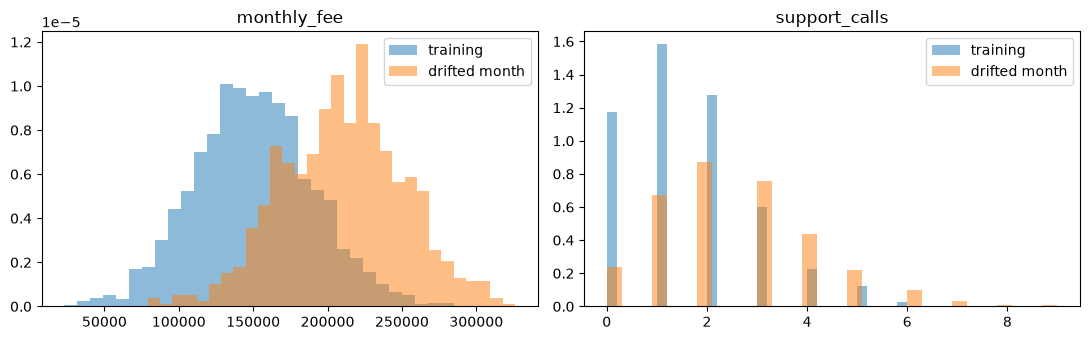

In [10]:
for name, live in [('stable month', live_stable), ('drifted month', live_drift)]:
    proba = pipeline.predict_proba(live[FEATURES])[:, 1]
    auc = roc_auc_score(live['churn'], proba)
    print(f'{name:>14}: mean predicted churn = {proba.mean():.3f}, '
          f'actual churn = {live["churn"].mean():.3f}, ROC AUC = {auc:.3f}')

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for ax, col in zip(axes, ['monthly_fee', 'support_calls']):
    ax.hist(X_train[col].dropna(), bins=30, alpha=0.5, density=True, label='training')
    ax.hist(live_drift[col].dropna(), bins=30, alpha=0.5, density=True, label='drifted month')
    ax.set_title(col)
    ax.legend()
plt.tight_layout()
plt.show()

For the stable month, the drift statistics stay low and no alert is raised. For the shifted month, `monthly_fee` and `support_calls` show large PSI values and tiny KS p-values, and the histograms confirm that their distributions have moved. The gap between predicted and actual churn also changes. In practice, these checks run automatically on a schedule and trigger an alert or a retraining job when drift appears. When true labels arrive later, performance metrics such as ROC AUC are tracked as well.

## 9. Retraining and the Model Lifecycle

No model works well forever. A typical production lifecycle (**MLOps**) includes:
1. **Train and validate** the pipeline, recording metrics and metadata.
2. **Version and register** the model (e.g., with MLflow), so any version can be traced and rolled back.
3. **Deploy** it behind an API or in a batch job, usually in a container.
4. **Monitor** input drift, prediction distributions, latency, errors, and (when labels arrive) accuracy.
5. **Retrain** on fresh data when drift or performance drops are detected, then compare the new model with the current one before replacing it (for example with A/B testing or a shadow deployment).

Because the entire preprocessing and model live in one pipeline, retraining is simply calling `fit()` on new data and saving a new versioned file.

In [11]:
recent = pd.concat([data, live_drift], ignore_index=True)
X_new_tr, X_new_te, y_new_tr, y_new_te = train_test_split(
    recent[FEATURES], recent['churn'], test_size=0.2, random_state=42, stratify=recent['churn'])

from sklearn.base import clone
pipeline_v2 = clone(pipeline).fit(X_new_tr, y_new_tr)

drift_eval = live_drift.sample(400, random_state=0)
for name, m in [('v1.0.0 (old data)', pipeline), ('v1.1.0 (retrained)', pipeline_v2)]:
    auc = roc_auc_score(drift_eval['churn'], m.predict_proba(drift_eval[FEATURES])[:, 1])
    print(f'{name:>19}: ROC AUC on recent customers = {auc:.3f}')

joblib.dump(pipeline_v2, MODEL_DIR / 'churn_pipeline_v1.1.0.joblib', compress=3)
print('\nSaved files:', sorted(p.name for p in MODEL_DIR.iterdir()))

  v1.0.0 (old data): ROC AUC on recent customers = 0.793
 v1.1.0 (retrained): ROC AUC on recent customers = 0.924

Saved files: ['churn_pipeline.joblib', 'churn_pipeline.pkl', 'churn_pipeline_metadata.json', 'churn_pipeline_v1.1.0.joblib']


`clone()` creates a fresh, unfitted copy of the pipeline with the same settings, which is then trained on data that includes the new population. Both versions are compared on recent customers before deciding whether to switch. (This quick comparison reuses some recent customers seen in retraining, so in a real system the comparison would use a separate, newer holdout period.) The new version is saved as a separate file, so the previous one remains available for rollback.

## Chapter Summary

- Deploy the **entire pipeline**, not just the model, to avoid training-serving skew; make it robust with imputers and `handle_unknown='ignore'`.
- Save models with **joblib** (or pickle). Only load files from trusted sources, and match library versions; **skops** and **ONNX** are safer or more portable alternatives.
- Store **metadata** (versions, features, metrics, training statistics) next to every model file.
- Wrap the model in a function or service that **validates input** and returns clear responses or errors.
- Serve predictions through a **REST API** (e.g., FastAPI) for real-time use, or with **batch jobs** for large volumes; batch inference is far more efficient per record.
- **Monitor** deployed models for **data drift** using tests such as KS and PSI, as well as performance when labels become available.
- Follow an **MLOps lifecycle**: version, deploy, monitor, retrain, and compare new models against the current one before replacing it.